In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle, os
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

INPUT_DIR  = Path('/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed')
WORK_DIR   = Path('/kaggle/working')
IMAGE_DIR  = INPUT_DIR / 'images' / 'images' / 'image_train'  # double images/

random_state = 42
print("✅ Imports OK")
print(f"Image dir existe : {IMAGE_DIR.exists()}")

✅ Imports OK
Image dir existe : True


In [7]:
df_train = pd.read_csv(INPUT_DIR / 'df_train.csv', index_col=0)
df_val   = pd.read_csv(INPUT_DIR / 'df_val.csv',   index_col=0)
df_test  = pd.read_csv(INPUT_DIR / 'df_test.csv',  index_col=0)

print(f"Train : {df_train.shape}")
print(f"Val   : {df_val.shape}")
print(f"Test  : {df_test.shape}")
print(f"\nColonnes : {df_train.columns.tolist()}")
display(df_train.head(3))

# Détection automatique colonne texte
for col in ['text_lemmatise', 'text_fr', 'text']:
    if col in df_train.columns:
        TEXT_COL = col
        break
print(f"\n✅ Colonne texte : '{TEXT_COL}'")
print(f"Exemple : {df_train[TEXT_COL].iloc[0][:100]}...")

Train : (109566, 8)
Val   : (8492, 8)
Test  : (8492, 8)

Colonnes : ['productid', 'imageid', 'text_fr', 'lang', 'categorie', 'imagefile', 'text_lemmatise', 'prdtypecode']


,productid,imageid,text_fr,lang,categorie,imagefile,text_lemmatise,prdtypecode
0,131641431,885888766,Jesus - Cahiers Du Libre Avenir - Prêtre autre...,fr,Livre occasion,image_885888766_product_131641431.jpg,jesus cahiers libre avenir prêtre autrement,10
1,745789761,1304710852,Les arts de la paix sans gloire: expositions d...,en,Livre occasion,image_1304710852_product_745789761.jpg,art paix sans gloire exposition société canadi...,10
2,651353882,1033554185,Lecons De Sciences - Cours Superieur - Premier...,fr,Livre occasion,image_1033554185_product_651353882.jpg,lecons science cours superieur premiere annee ...,10



✅ Colonne texte : 'text_lemmatise'
Exemple : jesus cahiers libre avenir prêtre autrement...


In [8]:
X_train = df_train[TEXT_COL].fillna('').values
y_train = df_train['prdtypecode'].values

X_val   = df_val[TEXT_COL].fillna('').values
y_val   = df_val['prdtypecode'].values

X_test  = df_test[TEXT_COL].fillna('').values
y_test  = df_test['prdtypecode'].values

classes = sorted(df_train['prdtypecode'].unique())
print(f"✅ {len(X_train):,} textes train | {len(classes)} classes")
print(f"   {len(X_val):,} textes val")
print(f"   {len(X_test):,} textes test")

✅ 109,566 textes train | 27 classes
   8,492 textes val
   8,492 textes test


In [9]:
print("⏳ Vectorisation TF-IDF...")

tfidf = TfidfVectorizer(
    max_features=100_000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word',
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf   = tfidf.transform(X_val)
X_test_tfidf  = tfidf.transform(X_test)

print(f"✅ TF-IDF OK")
print(f"   Vocabulaire   : {len(tfidf.vocabulary_):,} tokens")
print(f"   Matrice train : {X_train_tfidf.shape}")

⏳ Vectorisation TF-IDF...
✅ TF-IDF OK
   Vocabulaire   : 100,000 tokens
   Matrice train : (109566, 100000)


In [10]:
models_to_try = {
    'LinearSVC (C=0.1)' : LinearSVC(C=0.1, max_iter=2000, random_state=42),
    'LinearSVC (C=1)'   : LinearSVC(C=1.0, max_iter=2000, random_state=42),
    'LinearSVC (C=5)'   : LinearSVC(C=5.0, max_iter=2000, random_state=42),
    'LogisticRegression': LogisticRegression(max_iter=1000, solver='saga',
                                             n_jobs=-1, random_state=42),
}

results = {}
trained_models = {}

print("⏳ Entraînement des modèles...\n")
for name, model in models_to_try.items():
    model.fit(X_train_tfidf, y_train)
    f1_v = f1_score(y_val,  model.predict(X_val_tfidf),  average='weighted')
    f1_t = f1_score(y_test, model.predict(X_test_tfidf), average='weighted')
    results[name] = {'F1 Val': round(f1_v, 4), 'F1 Test': round(f1_t, 4)}
    trained_models[name] = model
    print(f"   {name:<28} Val: {f1_v:.4f}  Test: {f1_t:.4f}")

df_results = pd.DataFrame(results).T.sort_values('F1 Val', ascending=False)
print(f"\n🏆 Meilleur modèle : {df_results.index[0]}")
display(df_results)

⏳ Entraînement des modèles...

   LinearSVC (C=0.1)            Val: 0.8087  Test: 0.8074
   LinearSVC (C=1)              Val: 0.8171  Test: 0.8121
   LinearSVC (C=5)              Val: 0.8059  Test: 0.8016
   LogisticRegression           Val: 0.8092  Test: 0.8056

🏆 Meilleur modèle : LinearSVC (C=1)


,F1 Val,F1 Test
LinearSVC (C=1),0.8171,0.8121
LogisticRegression,0.8092,0.8056
LinearSVC (C=0.1),0.8087,0.8074
LinearSVC (C=5),0.8059,0.8016


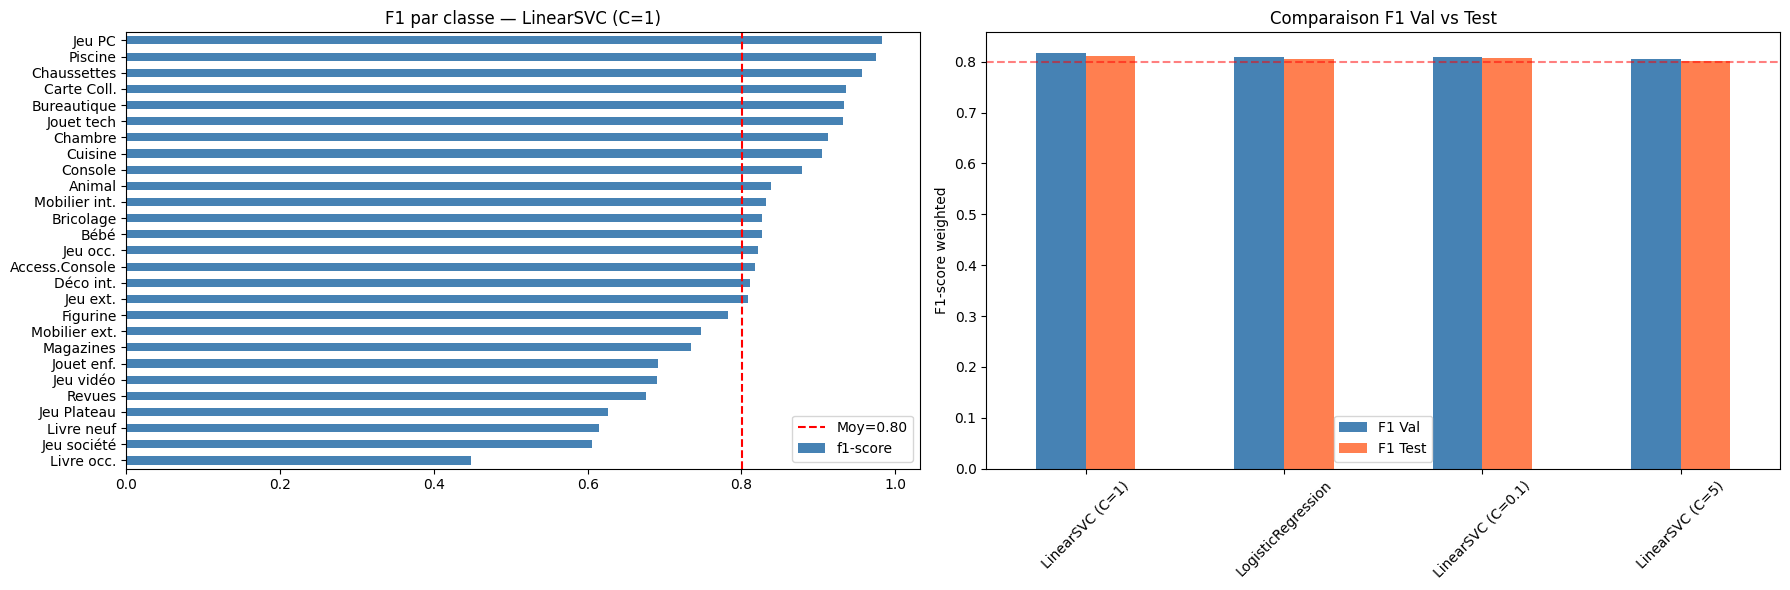

In [11]:
best_name  = df_results.index[0]
best_model = trained_models[best_name]
y_pred     = best_model.predict(X_test_tfidf)

prdcodetype2label = {
    10:'Livre occ.', 40:'Jeu vidéo', 50:'Access.Console',
    60:'Console', 1140:'Figurine', 1160:'Carte Coll.',
    1180:'Jeu Plateau', 1280:'Jouet enf.', 1281:'Jeu société',
    1300:'Jouet tech', 1301:'Chaussettes', 1302:'Jeu ext.',
    1320:'Bébé', 1560:'Mobilier int.', 1920:'Chambre',
    1940:'Cuisine', 2060:'Déco int.', 2220:'Animal',
    2280:'Revues', 2403:'Magazines', 2462:'Jeu occ.',
    2522:'Bureautique', 2582:'Mobilier ext.', 2583:'Piscine',
    2585:'Bricolage', 2705:'Livre neuf', 2905:'Jeu PC',
}
labels_str = [prdcodetype2label.get(c, str(c)) for c in classes]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# F1 par classe
report = classification_report(y_test, y_pred,
                                target_names=labels_str, output_dict=True)
df_rep = pd.DataFrame(report).T.iloc[:-3]
df_rep['f1-score'].sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].axvline(df_rep['f1-score'].mean(), color='red',
                linestyle='--', label=f"Moy={df_rep['f1-score'].mean():.2f}")
axes[0].set_title(f"F1 par classe — {best_name}", fontsize=12)
axes[0].legend()

# Comparaison modèles
df_results.plot(kind='bar', ax=axes[1], color=['steelblue','coral'])
axes[1].set_title("Comparaison F1 Val vs Test", fontsize=12)
axes[1].set_ylabel("F1-score weighted")
axes[1].tick_params(axis='x', rotation=45)
axes[1].axhline(0.8, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(WORK_DIR / 'tfidf_svc_results.png', dpi=150, bbox_inches='tight')
plt.show()

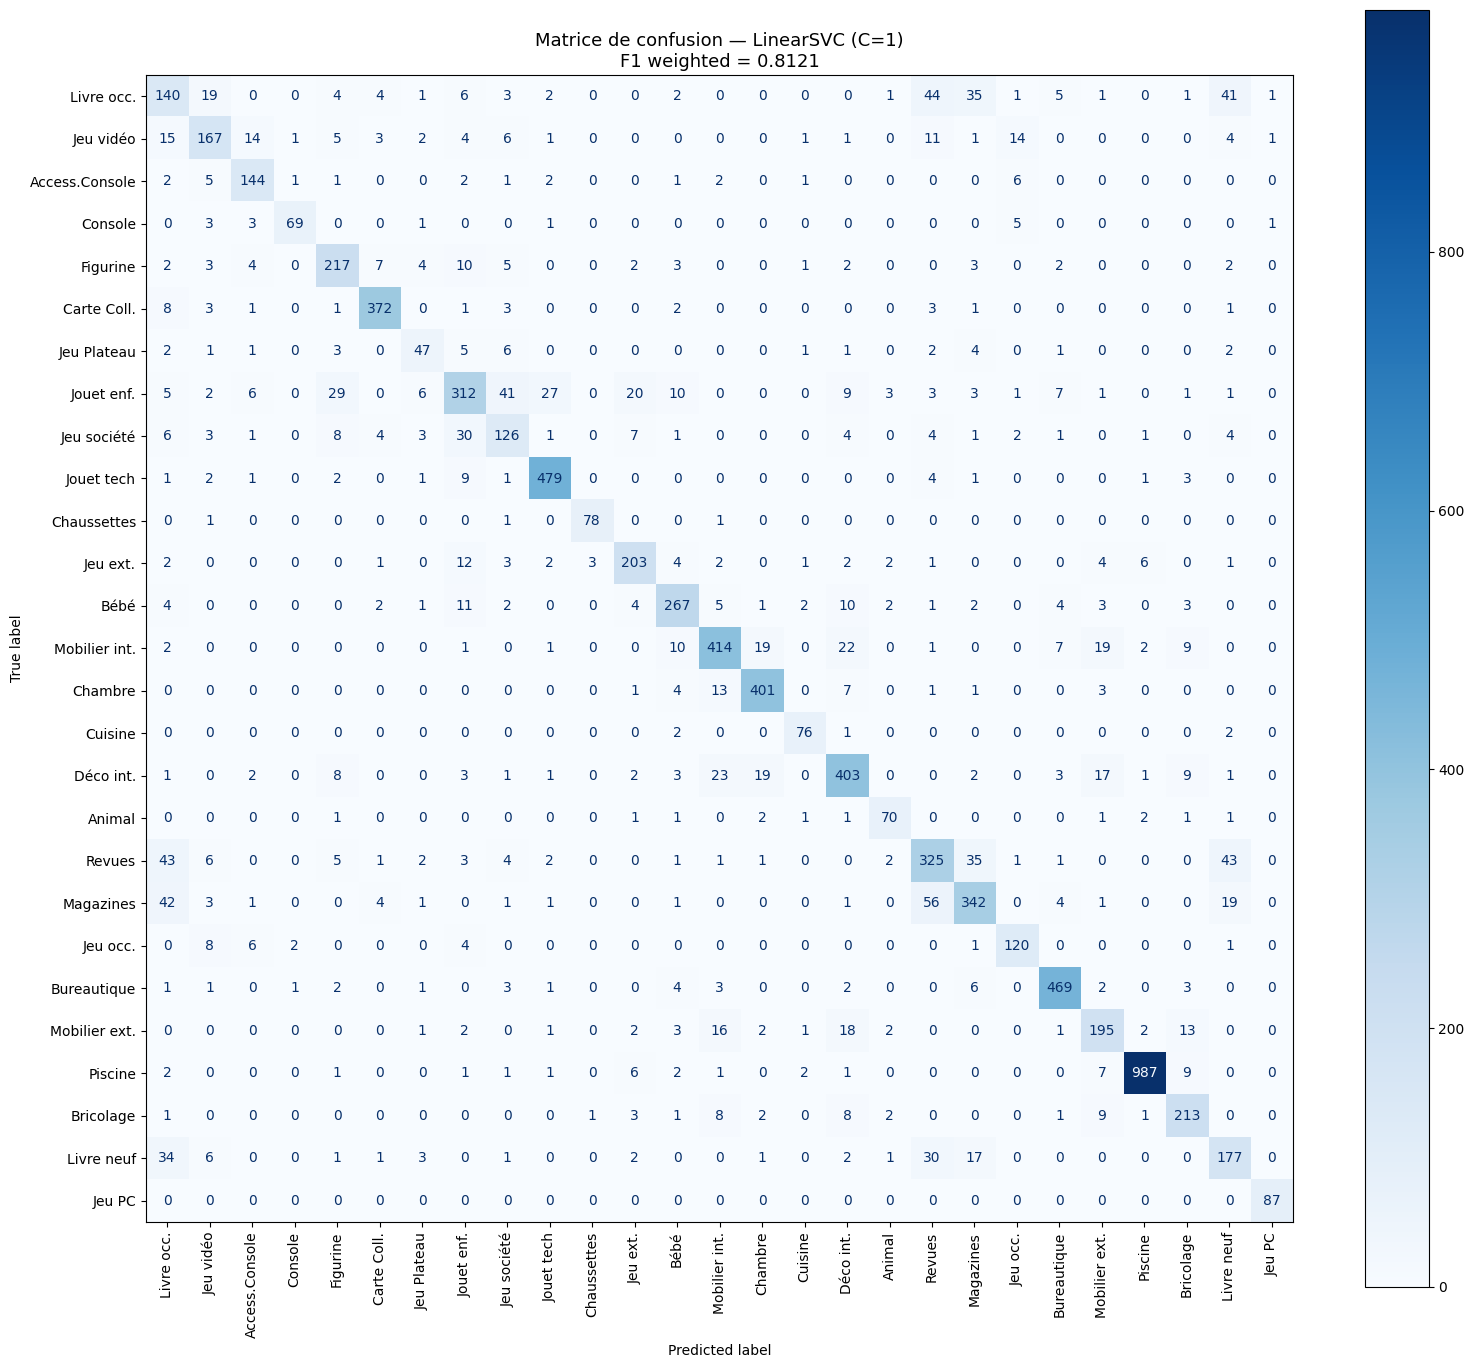


📉 5 classes les plus difficiles :
             precision    recall  f1-score
Livre occ.    0.447284  0.450161  0.448718
Jeu société   0.602871  0.608696  0.605769
Livre neuf    0.590000  0.641304  0.614583
Jeu Plateau   0.635135  0.618421  0.626667
Revues        0.668724  0.682773  0.675676

📈 5 classes les mieux prédites :
             precision    recall  f1-score
Jeu PC        0.966667  1.000000  0.983051
Piscine       0.984048  0.966699  0.975296
Chaussettes   0.951220  0.962963  0.957055
Carte Coll.   0.932331  0.939394  0.935849
Bureautique   0.926877  0.939880  0.933333


In [12]:
cm   = confusion_matrix(y_test, y_pred, labels=classes)
fig, ax = plt.subplots(figsize=(16, 14))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=labels_str).plot(
    ax=ax, xticks_rotation=90, colorbar=True, cmap='Blues')
ax.set_title(f"Matrice de confusion — {best_name}\n"
             f"F1 weighted = {f1_score(y_test,y_pred,average='weighted'):.4f}",
             fontsize=13)
plt.tight_layout()
plt.savefig(WORK_DIR / 'confusion_matrix_tfidf.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📉 5 classes les plus difficiles :")
print(df_rep.nsmallest(5,'f1-score')[['precision','recall','f1-score']])
print("\n📈 5 classes les mieux prédites :")
print(df_rep.nlargest(5,'f1-score')[['precision','recall','f1-score']])

In [13]:
# Modèle + vectoriseur
model_data = {
    'tfidf'      : tfidf,
    'model'      : best_model,
    'model_name' : best_name,
    'classes'    : classes,
    'f1_val'     : df_results.loc[best_name, 'F1 Val'],
    'f1_test'    : df_results.loc[best_name, 'F1 Test'],
}
with open(WORK_DIR / 'tfidf_svc_model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

# Scores pour la fusion (decision_function = distances aux hyperplans)
np.save(WORK_DIR / 'tfidf_svc_val_scores.npy',
        best_model.decision_function(X_val_tfidf))
np.save(WORK_DIR / 'tfidf_svc_test_scores.npy',
        best_model.decision_function(X_test_tfidf))

print("✅ Fichiers sauvegardés dans /kaggle/working/ :")
for f in sorted(WORK_DIR.iterdir()):
    print(f"   {f.name:<40} {f.stat().st_size/1024/1024:.1f} MB")

print(f"\n🏆 Résumé :")
print(f"   Modèle  : {best_name}")
print(f"   F1 Val  : {df_results.loc[best_name,'F1 Val']:.4f}")
print(f"   F1 Test : {df_results.loc[best_name,'F1 Test']:.4f}")

✅ Fichiers sauvegardés dans /kaggle/working/ :
   .virtual_documents                       0.0 MB
   confusion_matrix_tfidf.png               0.3 MB
   tfidf_svc_model.pkl                      24.6 MB
   tfidf_svc_results.png                    0.1 MB
   tfidf_svc_test_scores.npy                1.7 MB
   tfidf_svc_val_scores.npy                 1.7 MB

🏆 Résumé :
   Modèle  : LinearSVC (C=1)
   F1 Val  : 0.8171
   F1 Test : 0.8121
